###  ==================================================
# TASK 2: CALIFORNIA HOUSING PRICE PREDICTION
### ==================================================

# 1. IMPORT LIBRARIES

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import warnings
warnings.filterwarnings("ignore")

###### ==========================================================
# 2. LOAD DATASET
###### ==========================================================

In [3]:
df = pd.read_csv("housing.csv")
print("Dataset Loaded Successfully!")
print("\nFirst 5 Rows:")
print(df.head())

Dataset Loaded Successfully!

First 5 Rows:
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  


##### ==========================================================
## 3. BASIC DATASET INFORMATION
##### ==========================================================

In [4]:
print("\nDataset Shape:")
print(df.shape)
print("\nDataset Information:")
df.info()
print("\nStatistical Summary:")
print(df.describe())
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Rows:")
print(df.duplicated().sum())
print("\nOcean Proximity Values:")
print(df["ocean_proximity"].value_counts())


Dataset Shape:
(20640, 10)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Statistical Summary:
          longitude      latitude  housing_median_age   total_rooms  \
count  20640.000000  20640.000000        20640.000000  20640.000000   
mean    -119.569704     35.631861    

##### ==========================================================
# 4. EXPLORATORY DATA ANALYSIS (EDA)
##### ==========================================================

# Distribution of house prices

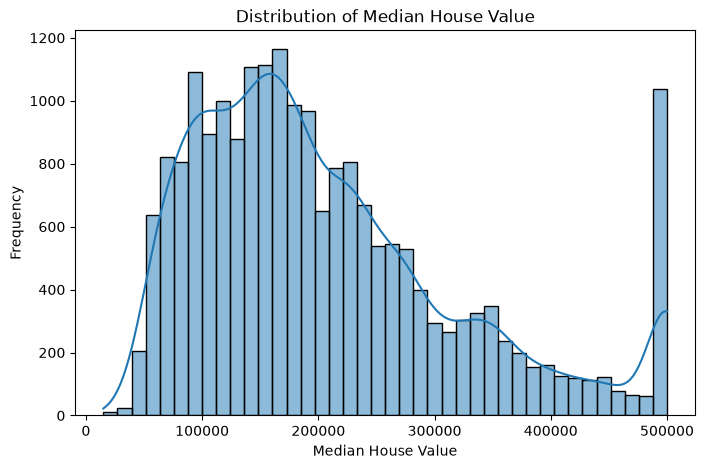

In [5]:
plt.figure(figsize=(8, 5))
sns.histplot(df["median_house_value"], bins=40, kde=True)
plt.title("Distribution of Median House Value")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")
plt.show()

# Correlation Heatmap

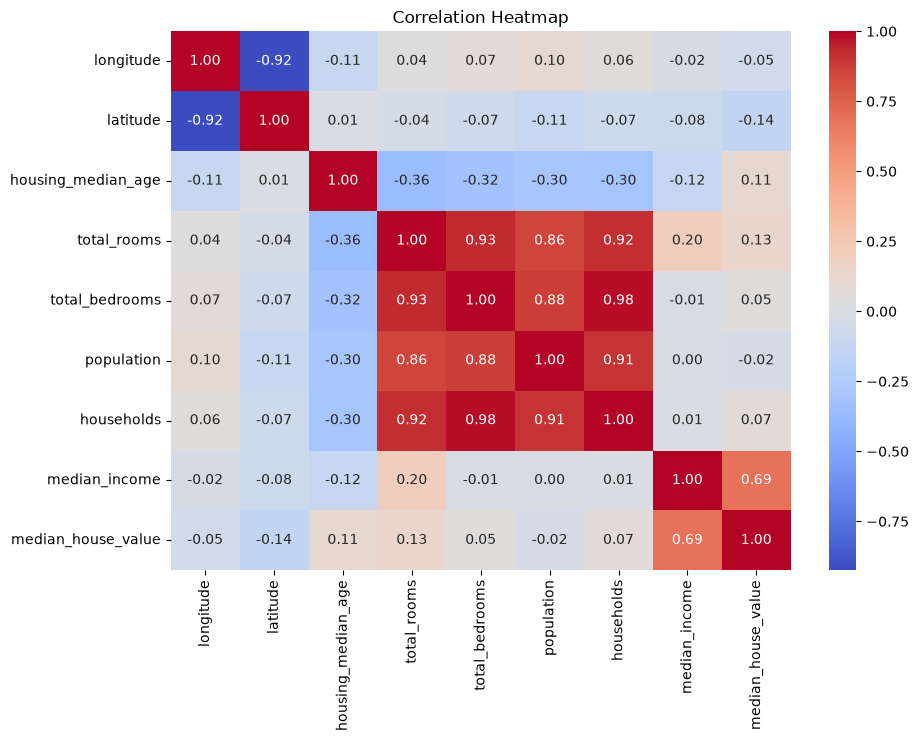

In [6]:
plt.figure(figsize=(10, 7))
correlation = df.select_dtypes(include=np.number).corr()
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()

# House prices based on ocean proximity

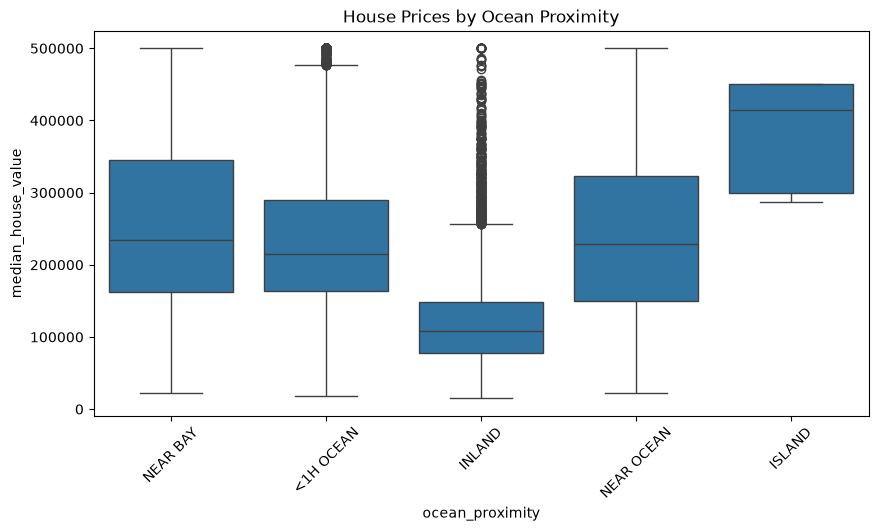

In [7]:
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df,
    x="ocean_proximity",
    y="median_house_value"
)
plt.title("House Prices by Ocean Proximity")
plt.xticks(rotation=45)
plt.show()

##### ==========================================================
# 5. HANDLE MISSING VALUES
##### ==========================================================

In [8]:
print("\nMissing Values Before Handling:")
print(df.isnull().sum())


Missing Values Before Handling:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


##### total_bedrooms has missing values.
##### We will handle missing values using SimpleImputer
##### inside the machine learning pipeline.

###### ==========================================================
#### 6. SEPARATE FEATURES AND TARGET
###### ==========================================================

In [9]:
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]
print("\nFeatures:")
print(X.head())
print("\nTarget:")
print(y.head())


Features:
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income ocean_proximity  
0       322.0       126.0         8.3252        NEAR BAY  
1      2401.0      1138.0         8.3014        NEAR BAY  
2       496.0       177.0         7.2574        NEAR BAY  
3       558.0       219.0         5.6431        NEAR BAY  
4       565.0       259.0         3.8462        NEAR BAY  

Target:
0    452600.0
1    358500.0
2    352100.0
3    341300.0
4    342200.0
Name: median_house_value, dtype: float64


###### ==========================================================
##### 7. IDENTIFY NUMERICAL AND CATEGORICAL COLUMNS
###### ==========================================================

In [10]:
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()
categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()
print("\nNumerical Features:")
print(numeric_features)
print("\nCategorical Features:")
print(categorical_features)


Numerical Features:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']

Categorical Features:
['ocean_proximity']


###### ==========================================================
##### 8. MULTICOLLINEARITY CHECK USING VIF
###### ==========================================================

# Fill missing numerical values for VIF calculation

In [11]:
vif_data = X[numeric_features].copy()
imputer_vif = SimpleImputer(strategy="median")
vif_data = pd.DataFrame(
    imputer_vif.fit_transform(vif_data),
    columns=numeric_features
)
# Add constant
vif_data = sm.add_constant(vif_data)

# Calculate VIF

In [12]:
vif_result = pd.DataFrame()
vif_result["Feature"] = vif_data.columns
vif_result["VIF"] = [
    variance_inflation_factor(
        vif_data.values, i
    )
    for i in range(vif_data.shape[1])
]
print("\nVIF Results:")
print(vif_result)


VIF Results:
              Feature        VIF
0               const   1.000000
1           longitude   8.703623
2            latitude   8.826607
3  housing_median_age   1.259064
4         total_rooms  12.126382
5      total_bedrooms  26.882085
6          population   6.261680
7          households  28.284141
8       median_income   1.688920


###### ==========================================================
#### 9. TRAIN TEST SPLIT
###### ==========================================================

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)


Training Data Shape: (16512, 9)
Testing Data Shape: (4128, 9)


###### ==========================================================
#### 10. NUMERICAL FEATURE PIPELINE
###### ==========================================================

In [14]:
numeric_transformer = Pipeline(
    steps=[
        # Handle missing numerical values
        ("imputer", SimpleImputer(strategy="median")),
        # Scale numerical features
        ("scaler1", StandardScaler()),
        # Create interaction features
        ("poly", PolynomialFeatures(
            degree=2,
            interaction_only=True,
            include_bias=False
        )),
        # Scale transformed features
        ("scaler2", StandardScaler())
    ]
)

###### ==========================================================
#### 11. CATEGORICAL FEATURE PIPELINE
###### ==========================================================

In [15]:
categorical_transformer = Pipeline(
    steps=[
        # Handle missing categorical values
        ("imputer", SimpleImputer(strategy="most_frequent")),
        # Convert categories into numerical values
        ("encoder", OneHotEncoder(
            handle_unknown="ignore"
        ))

    ]
)

###### ==========================================================
#### 12. COMBINE BOTH PIPELINES
###### ==========================================================

In [16]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

###### ==========================================================
#### 13. LINEAR REGRESSION MODEL
###### ==========================================================

In [17]:
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)
linear_model.fit(X_train, y_train)
linear_predictions = linear_model.predict(X_test)

###### ==========================================================
#### 14. RIDGE REGRESSION MODEL
###### ==========================================================

In [18]:
ridge_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", Ridge())
    ]
)
ridge_model.fit(X_train, y_train)
ridge_predictions = ridge_model.predict(X_test)

###### ==========================================================
#### 15. LASSO REGRESSION MODEL
###### ==========================================================

In [19]:
lasso_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", Lasso(max_iter=10000))
    ]
)
lasso_model.fit(X_train, y_train)
lasso_predictions = lasso_model.predict(X_test)

###### ==========================================================
#### 16. EVALUATION FUNCTION
###### ==========================================================

In [20]:
def evaluate_model(name, y_true, predictions):
    mse = mean_squared_error(y_true, predictions)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, predictions)
    r2 = r2_score(y_true, predictions)
    print("\n", name)
    print("RMSE:", rmse)
    print("MAE:", mae)
    print("R2 Score:", r2)
    return {
        "Model": name,
        "RMSE": rmse,
        "MAE": mae,
        "R2 Score": r2
    }

###### ==========================================================
#### 17. COMPARE ALL THREE MODELS
###### ==========================================================

In [21]:
results = []
results.append(
    evaluate_model(
        "Linear Regression",
        y_test,
        linear_predictions
    )
)
results.append(
    evaluate_model(
        "Ridge Regression",
        y_test,
        ridge_predictions
    )
)
results.append(
    evaluate_model(
        "Lasso Regression",
        y_test,
        lasso_predictions
    )
)


 Linear Regression
RMSE: 66788.2959625058
MAE: 47282.11095041735
R2 Score: 0.6595966181822637

 Ridge Regression
RMSE: 66712.51368854663
MAE: 47249.68421144344
R2 Score: 0.660368666840258

 Lasso Regression
RMSE: 66780.07073228105
MAE: 47279.27964771333
R2 Score: 0.6596804569368091


# Create comparison DataFrame


In [22]:
results_df = pd.DataFrame(results)
print("\nModel Comparison:")
print(results_df)


Model Comparison:
               Model          RMSE           MAE  R2 Score
0  Linear Regression  66788.295963  47282.110950  0.659597
1   Ridge Regression  66712.513689  47249.684211  0.660369
2   Lasso Regression  66780.070732  47279.279648  0.659680


###### ==========================================================
#### 18. GRID SEARCH CV FOR RIDGE
###### ==========================================================

In [23]:
ridge_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", Ridge())
    ]
)
ridge_params = {
    "model__alpha": [0.1, 1, 10, 100]
}
ridge_grid = GridSearchCV(
    ridge_pipeline,
    ridge_params,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
ridge_grid.fit(X_train, y_train)
print("\nBest Ridge Parameters:")
print(ridge_grid.best_params_)
print("\nBest Ridge CV RMSE:")
print(-ridge_grid.best_score_)


Best Ridge Parameters:
{'model__alpha': 1}

Best Ridge CV RMSE:
64612.49938023812


###### ==========================================================
#### 19. GRID SEARCH CV FOR LASSO
###### ==========================================================

In [24]:
lasso_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", Lasso(max_iter=10000))
    ]
)
lasso_params = {
    "model__alpha": [0.001, 0.01, 0.1, 1, 10]
}
lasso_grid = GridSearchCV(
    lasso_pipeline,
    lasso_params,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
lasso_grid.fit(X_train, y_train)
print("\nBest Lasso Parameters:")
print(lasso_grid.best_params_)
print("\nBest Lasso CV RMSE:")
print(-lasso_grid.best_score_)


Best Lasso Parameters:
{'model__alpha': 1}

Best Lasso CV RMSE:
64619.041801682484


###### ==========================================================
#### 20. FINAL MODEL SELECTION
###### ==========================================================

# Select the model with the lowest cross-validation RMSE

In [25]:
if ridge_grid.best_score_ >= lasso_grid.best_score_:
    best_model = ridge_grid.best_estimator_
    best_model_name = "Ridge Regression"
else:
    best_model = lasso_grid.best_estimator_
    best_model_name = "Lasso Regression"
print("\nBest Model:", best_model_name)


Best Model: Ridge Regression


###### ==========================================================
#### 21. FINAL PREDICTIONS
###### ==========================================================

In [26]:
final_predictions = best_model.predict(X_test)
print("\nFinal Model Performance:")
final_results = evaluate_model(
    best_model_name,
    y_test,
    final_predictions
)


Final Model Performance:

 Ridge Regression
RMSE: 66712.51368854663
MAE: 47249.68421144344
R2 Score: 0.660368666840258


###### ==========================================================
#### 22. ACTUAL VS PREDICTED PLOT
###### ==========================================================

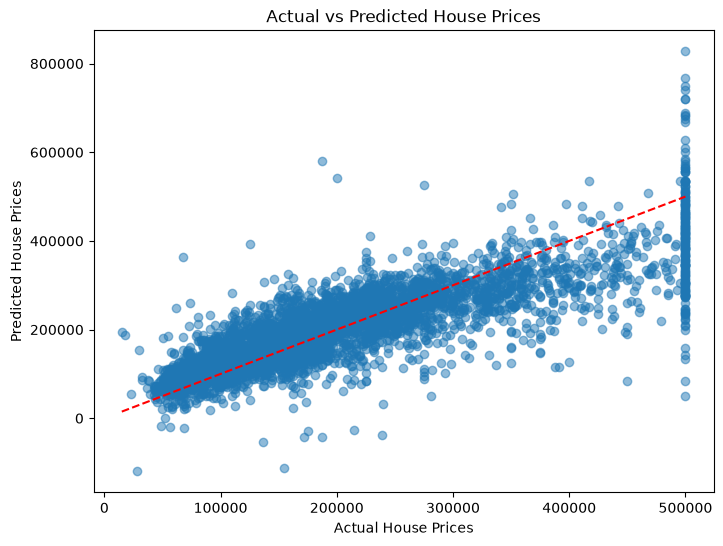

In [27]:
plt.figure(figsize=(8, 6))
plt.scatter(
    y_test,
    final_predictions,
    alpha=0.5
)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")
plt.show()

###### ==========================================================
#### 23. RESIDUAL PLOT
###### ==========================================================

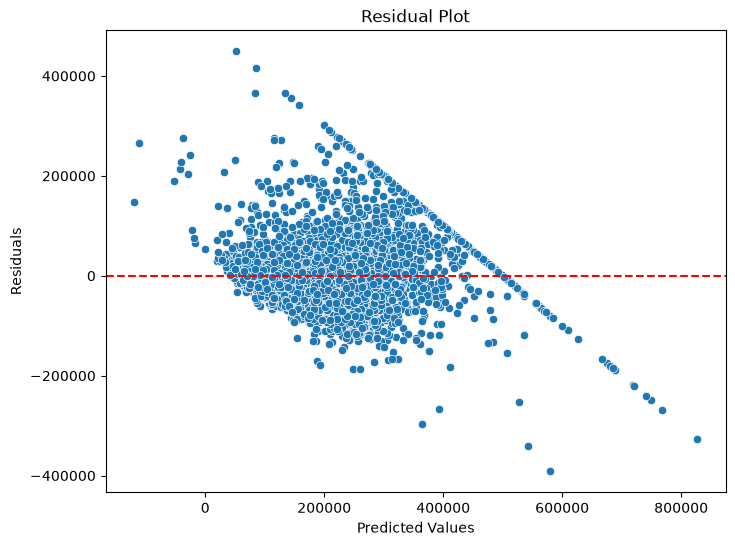

In [28]:
residuals = y_test - final_predictions
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=final_predictions,
    y=residuals
)
plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

###### ==========================================================
#### 24. RESIDUAL DISTRIBUTION
###### ==========================================================

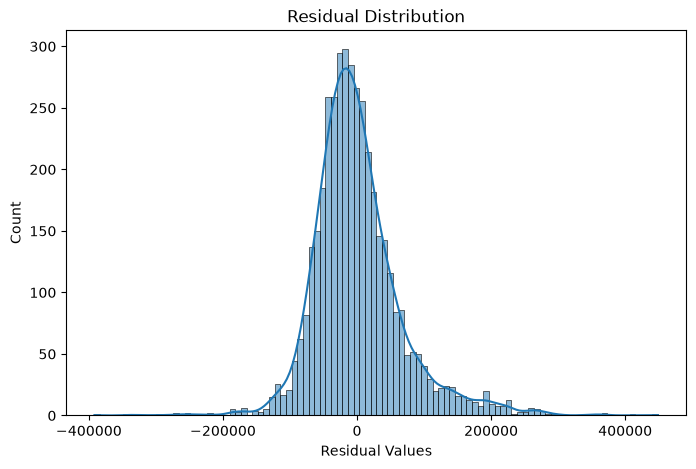

In [29]:
plt.figure(figsize=(8, 5))
sns.histplot(
    residuals,
    kde=True
)
plt.title("Residual Distribution")
plt.xlabel("Residual Values")
plt.show()

###### ==========================================================
#### 25. FINAL RESULT
###### ==========================================================

In [30]:
print("\n===================================")
print("CALIFORNIA HOUSING PRICE PREDICTION")
print("===================================")
print("Selected Model:", best_model_name)
print("RMSE:", np.sqrt(
    mean_squared_error(y_test, final_predictions)
))
print("MAE:", mean_absolute_error(
    y_test, final_predictions
))
print("R2 Score:", r2_score(
    y_test, final_predictions
))
print("===================================")


CALIFORNIA HOUSING PRICE PREDICTION
Selected Model: Ridge Regression
RMSE: 66712.51368854663
MAE: 47249.68421144344
R2 Score: 0.660368666840258
